# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p15"
subproj <- "AVGUSTINOVA_24_25"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
[26] 26 27 28 29 30

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "RERE"      "RPL11"     "RPS8"      "NFIA"      "RPL5"      "COL11A1"  
 [7] "RPS27A"    "RPL32"     "RBMS3"     "RPL29"     "ROBO2"     "CADM2"    
[13] "RPL24"     "MECOM"     "PCDH7"     "EPHA5"     "RPS3A"     "RPS23"    
[19] "FBN2"      "RPS14"     "RPS18"     "EEF1A1"    "EPHA7"     "LAMA2"    
[25] "RPS12"     "ARID1B"    "SEMA3C"    "SEMA3E"    "MEST"      "CNTNAP2"  
[31] "RPL7"      "RPS6"      "ALDH1A1"   "RPL12"     "RPL7A"     "RPS24"    
[37] "RPL27A"    "NEAT1"     "MALAT1"    "RPS3"      "RPL41"     "HMGA2"    
[43] "RPL6"      "LINC02306" "RPLP1"     "RPS15A"    "RPL26"     "RPL19"    
[49] "L3MBTL4"   "RPL17"     "RPS16"     "RPS19"     "RPL13A"    "RPS9"     
[55] "MIR99AHG"  "RPL3"      "FTX"       "PCDH11X"   "RPL10"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

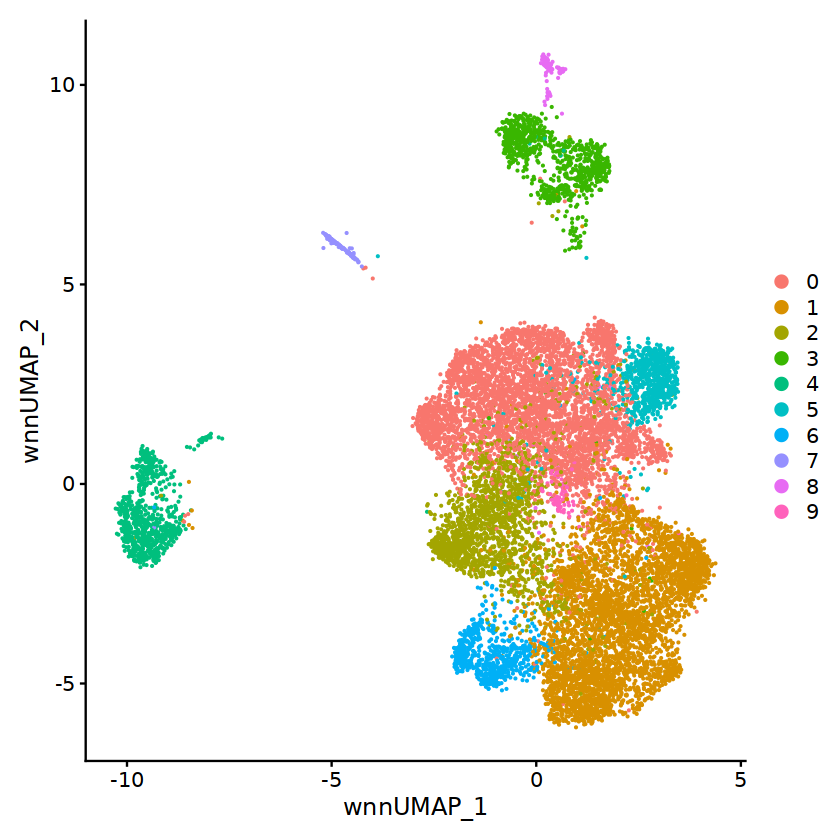

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

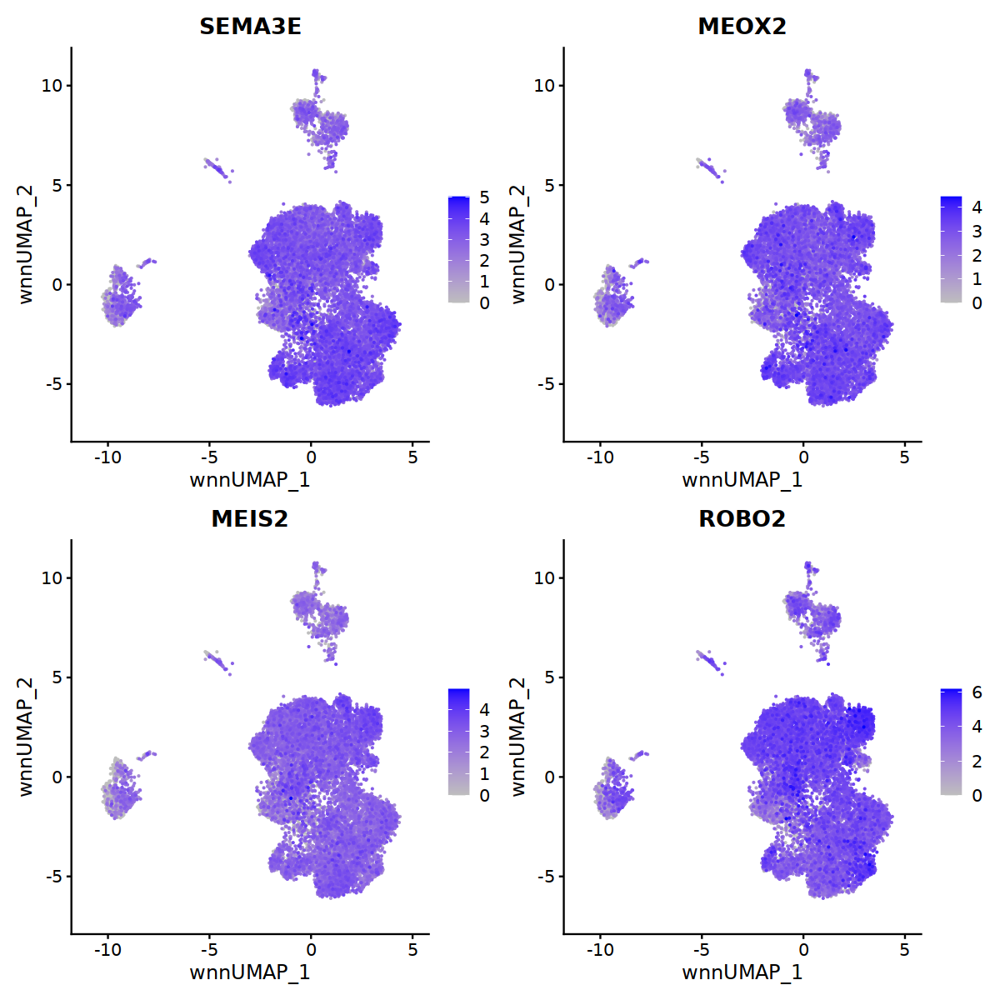

In [11]:
options(repr.plot.width = 10, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("SEMA3E","MEOX2", "MEIS2","ROBO2"),ncol=2,
            cols = c("gray", "blue"),  order=T)

## Re-normalize

Check whether DecontX has fixed enough the TYR expression in immune cells 

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

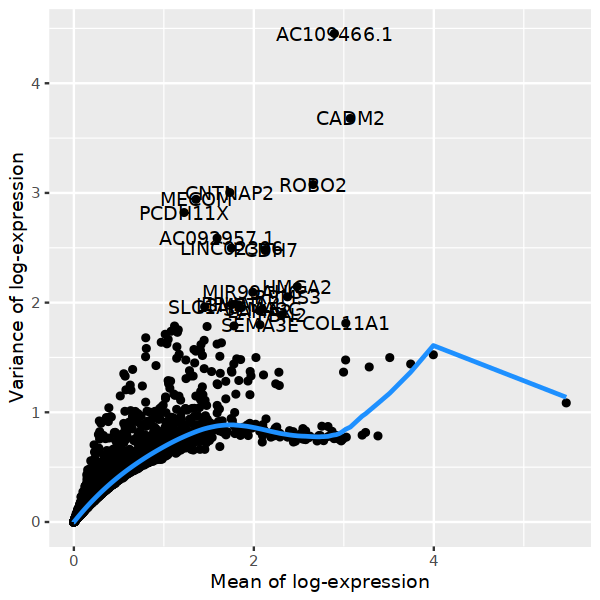

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 7581
[1] 7558


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  ZEB2, UTRN, LRMDA, PLXDC2, MAML2, RUNX1, DOCK10, DOCK4, ATXN1, PPP3CA 
	   ZSWIM6, NRIP1, A2M, MDFIC, TNS3, NR3C1, STARD13, IFI16, SLC9A9, MIR181A1HG 
	   RAB31, CHST11, ANKH, HDAC9, EPB41L2, SPATS2L, EPSTI1, DOCK8, DPYD, FRMD4B 
Negative:  AC109466.1, MEOX2, MID1, NOVA1, DNAH14, NR2F1-AS1, BMP5, MEIS2, PATJ, THSD7A 
	   NEGR1, AC092957.1, GAS2, ARHGAP28, LINC01122, AC008415.1, SEMA3A, NBEA, SNAP25, STAU2 
	   GRIP1, BMP6, ANO5, MIR4500HG, DOCK3, NTN4, ELAVL2, FLRT2, MSRB3, PTPRK 
PC_ 2 
Positive:  EBF1, SULF1, PRRX1, ZFPM2, COL6A3, SLIT2, FN1, IGFBP7, FBXL7, COL1A1 
	   CDH11, CCDC102B, ITGA1, COL1A2, EDNRA, COL12A1, SGIP1, BGN, PALM2-AKAP2, COL4A2 
	   SPARC, COL3A1, PDGFRB, COL4A1, CALD1, EDIL3, RBPMS, FAM155A, COL5A1, LAMA4 
Negative:  PTPRC, MSR1, SAMSN1, DOCK2, FRMD4B, ATP8B4, MARCH1, LYN, PIK3AP1, DOCK8 
	   FYB1, SYK, FMN1, MGAT4A, MS4A6A, CYBB, NPL, PDE4B, TBXAS1, PRKCB 
	   SLCO2B1, FMNL2, TFEC, SRGN, KCNMA1, ELMO1, APBB1IP

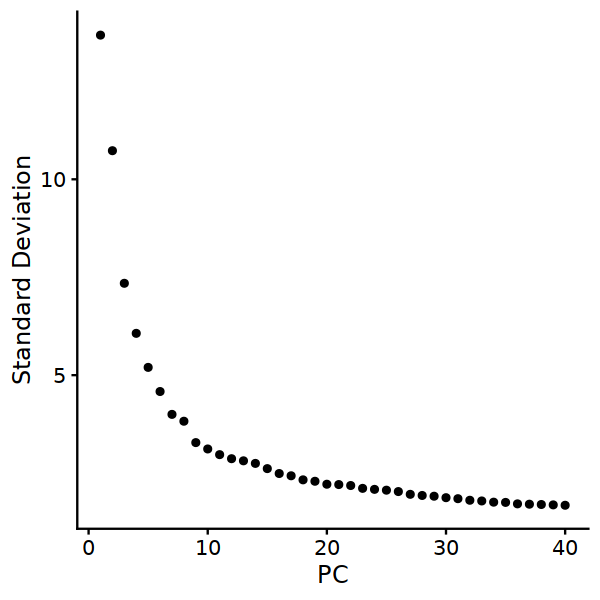

In [19]:
ElbowPlot(seurat_obj, n=40)

In [20]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


19:33:09 UMAP embedding parameters a = 0.9922 b = 1.112

19:33:09 Read 14122 rows and found 30 numeric columns

19:33:09 Using Annoy for neighbor search, n_neighbors = 30

19:33:09 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

19:33:11 Writing NN index file to temp file /scratch_tmp/49737069/RtmpZyWEkh/file236e86e78d10

19:33:11 Searching Annoy index using 1 thread, search_k = 3000

19:33:16 Annoy recall = 98.36%

19:33:17 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

19:33:17 285 smooth knn distance failures

19:33:19 Initializing from normalized Laplacian + noise (using irlba)

19:33:21 Commencing optimization for 200 epochs, with 588214 positive edges

19:33:41 Optimizatio

In [21]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [22]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells
)

19:34:28 UMAP embedding parameters a = 0.115 b = 1.929

19:34:29 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

19:34:29 265 smooth knn distance failures

19:34:31 Initializing from normalized Laplacian + noise (using irlba)

19:34:32 Commencing optimization for 200 epochs, with 428078 positive edges

19:34:53 Optimization finished



In [23]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 14122
Number of edges: 510257

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9798
Number of communities: 15
Elapsed time: 1 seconds


2 singletons identified. 13 final clusters.



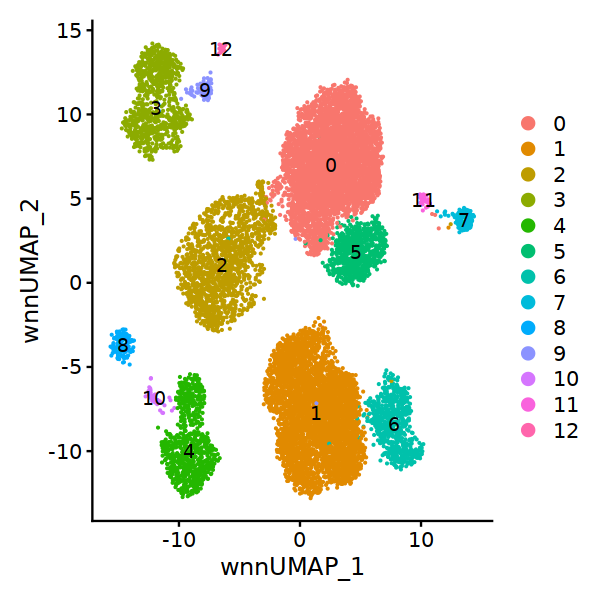

In [24]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

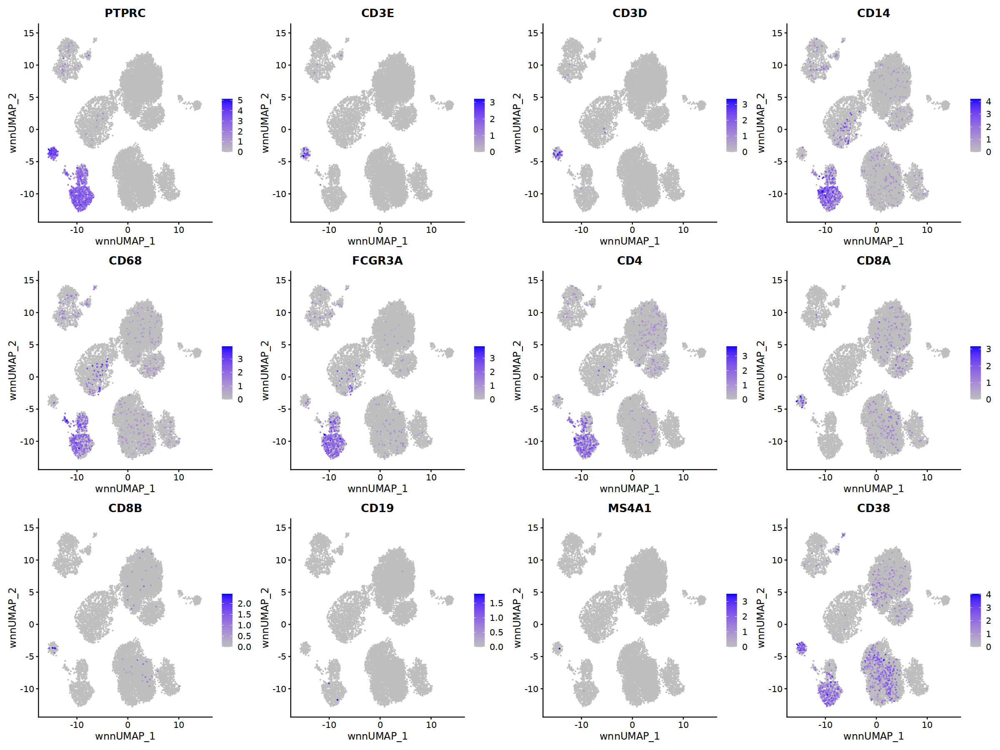

In [25]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

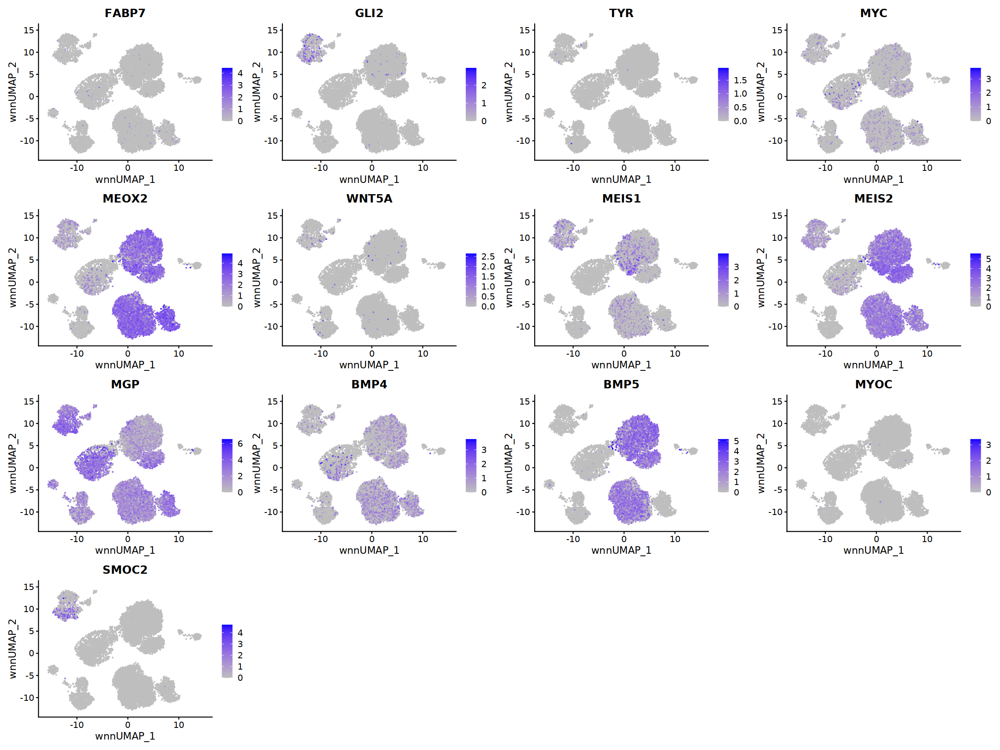

In [26]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

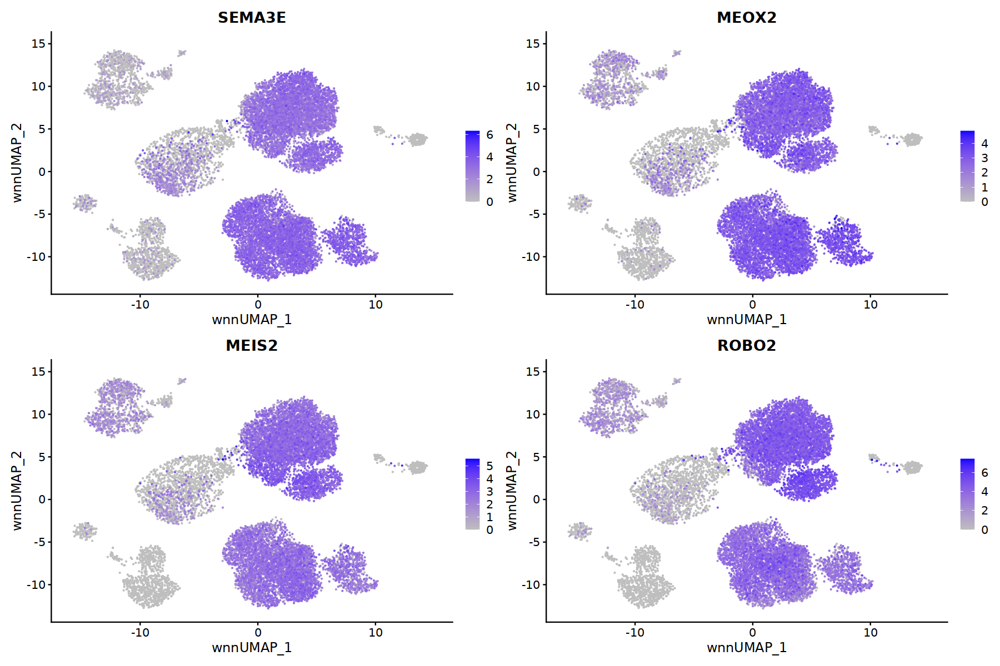

In [27]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("SEMA3E","MEOX2", "MEIS2","ROBO2"),ncol=2,
            cols = c("gray", "blue"),  order=T)

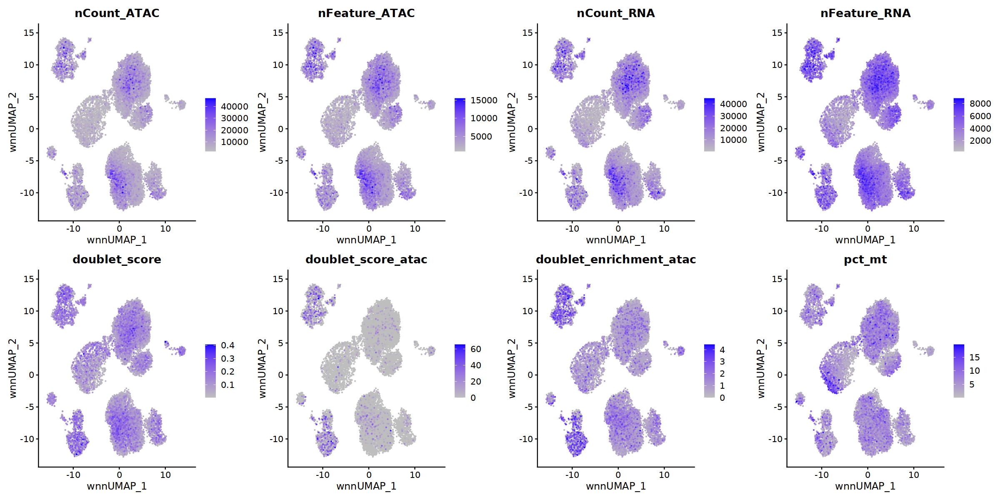

In [28]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

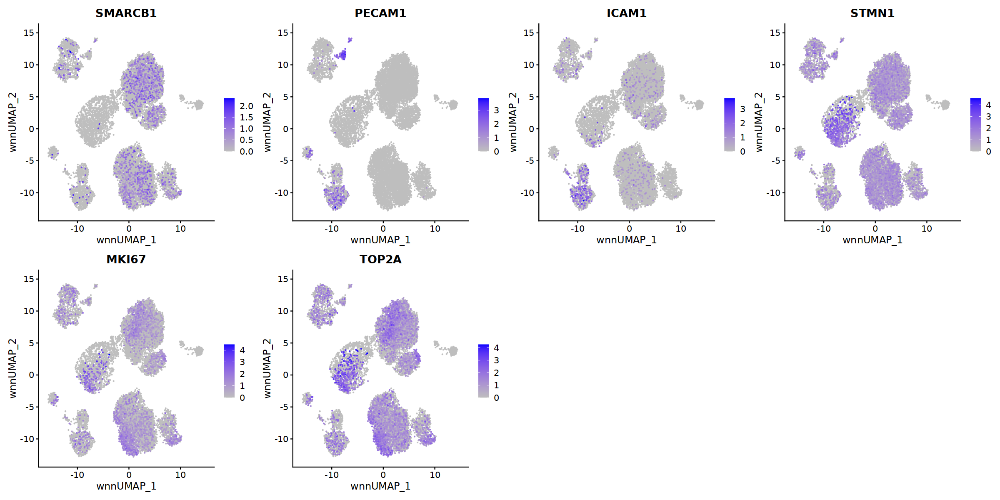

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [30]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12



In [31]:
rna.markers %>% 
  dplyr::filter(cluster == "4") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
LRMDA1,0.000000e+00,4.607749,0.936,0.051,0.000000e+00,4,LRMDA
PLXDC21,0.000000e+00,4.536969,0.926,0.046,0.000000e+00,4,PLXDC2
FMNL2,0.000000e+00,4.227288,0.927,0.380,0.000000e+00,4,FMNL2
DOCK41,0.000000e+00,4.194177,0.903,0.058,0.000000e+00,4,DOCK4
SPP1,0.000000e+00,3.968821,0.806,0.258,0.000000e+00,4,SPP1
FRMD4B,0.000000e+00,3.936345,0.846,0.013,0.000000e+00,4,FRMD4B
SLC9A9,0.000000e+00,3.850770,0.716,0.025,0.000000e+00,4,SLC9A9
MSR1,0.000000e+00,3.833070,0.786,0.006,0.000000e+00,4,MSR1
DOCK8,0.000000e+00,3.699084,0.832,0.021,0.000000e+00,4,DOCK8


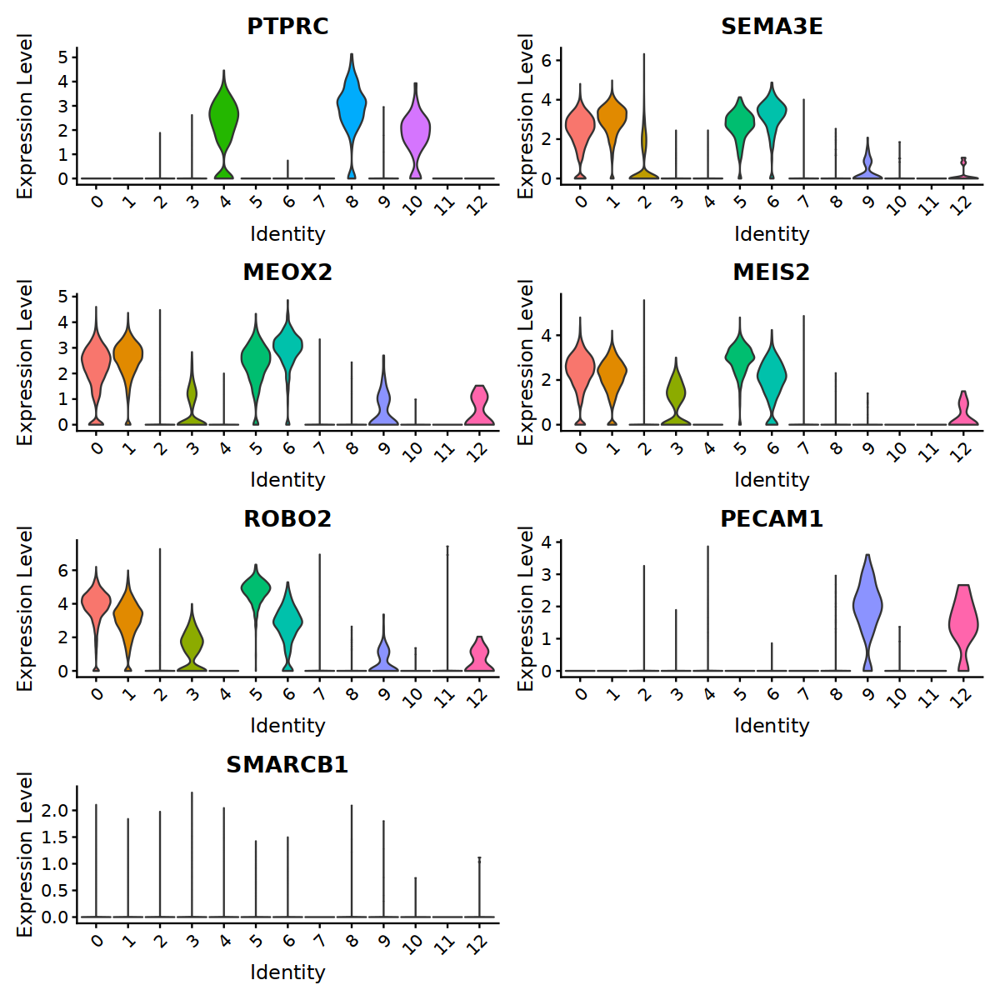

In [32]:
options(repr.plot.width = 10, repr.plot.height = 10)
VlnPlot(seurat_obj, 
            feature=c("PTPRC", "SEMA3E","MEOX2", "MEIS2","ROBO2", "PECAM1", "SMARCB1"),ncol=2,
            pt.size = 0)

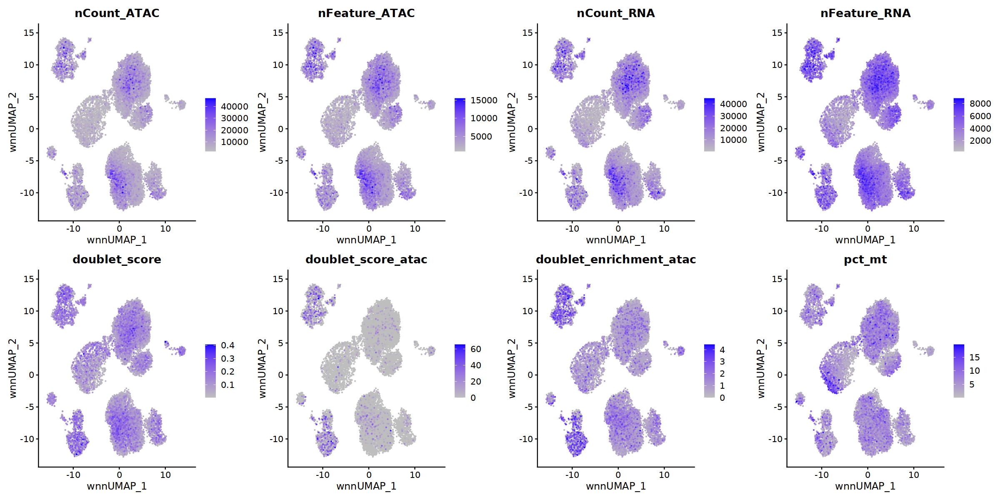

In [33]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

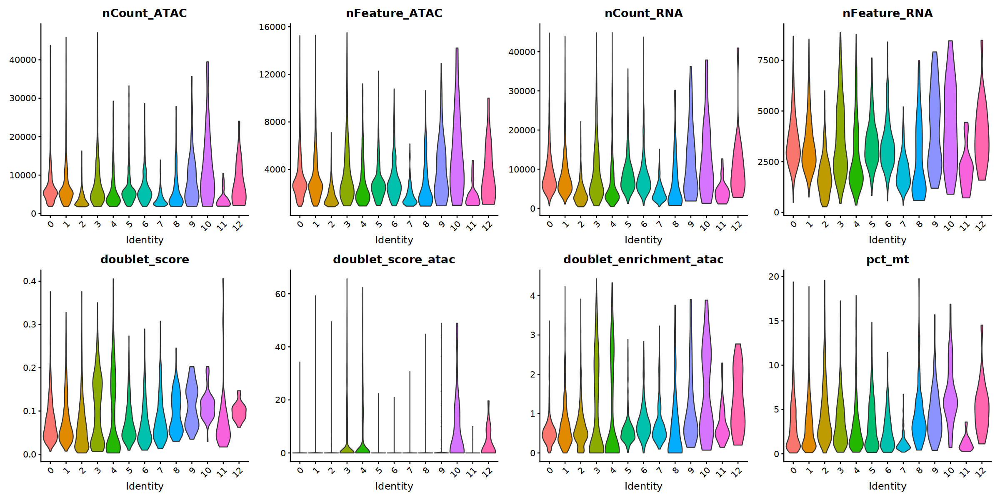

In [34]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

## Filter cells

low quality cells and doublets

In [35]:
seurat_obj <- subset(seurat_obj, idents = c("2", "7", "10","11"), invert = TRUE)

In [36]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [37]:
keep_peaks <- data.frame(rowSums(as.matrix(seurat_obj[['ATAC']]@counts)) >= 1)
colnames(keep_peaks) <- "logical"
keep_peaks <- subset(keep_peaks, logical==TRUE)
seurat_obj[['ATAC']]@counts <- seurat_obj[['ATAC']]@counts[rownames(keep_peaks), ]
seurat_obj[['ATAC']]@data <- seurat_obj[['ATAC']]@data[rownames(keep_peaks), ]

### RNA

In [38]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [39]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

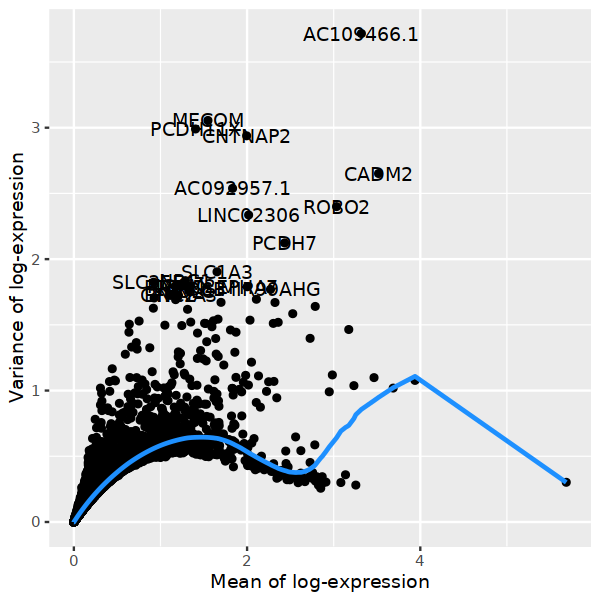

In [40]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [41]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 2274
[1] 2252


In [42]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AC109466.1, MEOX2, NR2F1-AS1, MID1, NOVA1, MEIS2, BMP5, PATJ, STAU2, NEGR1 
	   THSD7A, AC092957.1, GAS2, ARHGAP28, PTPRK, SEMA3A, LINC01122, AC008415.1, SNAP25, FLRT2 
	   GRIP1, BMP6, ANO5, MIR4500HG, NTN4, ELAVL2, AL136962.1, PDGFC, HHIP, PDE4D 
Negative:  ZEB2, LRMDA, UTRN, PLXDC2, MAML2, RUNX1, DOCK4, DOCK10, ATXN1, NRIP1 
	   ZSWIM6, SLC9A9, PPP3CA, A2M, DOCK8, CHST11, IFI16, NR3C1, STARD13, TNS3 
	   MDFIC, RAB31, FRMD4B, HDAC9, EPB41L2, ARHGAP15, EPSTI1, MIR181A1HG, CELF2, SPATS2L 
PC_ 2 
Positive:  EBF1, PRRX1, SULF1, FN1, COL6A3, ZFPM2, IGFBP7, SLIT2, COL1A1, ITGA1 
	   FBXL7, CCDC102B, COL1A2, CDH11, COL3A1, EDNRA, SPARC, COL12A1, PALM2-AKAP2, COL4A2 
	   SGIP1, COL4A1, EDIL3, PDGFRB, BGN, RBPMS, NR2F2-AS1, SOX5, LHFPL6, FAM155A 
Negative:  MSR1, SAMSN1, PTPRC, ATP8B4, MARCH1, DOCK2, FRMD4B, LYN, PIK3AP1, FYB1 
	   FMN1, SYK, DOCK8, FMNL2, CYBB, MS4A6A, MGAT4A, NPL, PDE4B, SLCO2B1 
	   TBXAS1, PRKCB, C1QB, TFEC, KCNMA1, SR

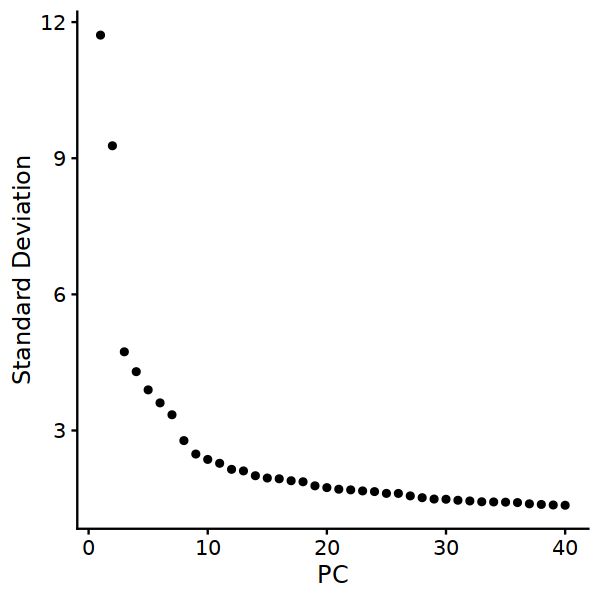

In [43]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [44]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [45]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



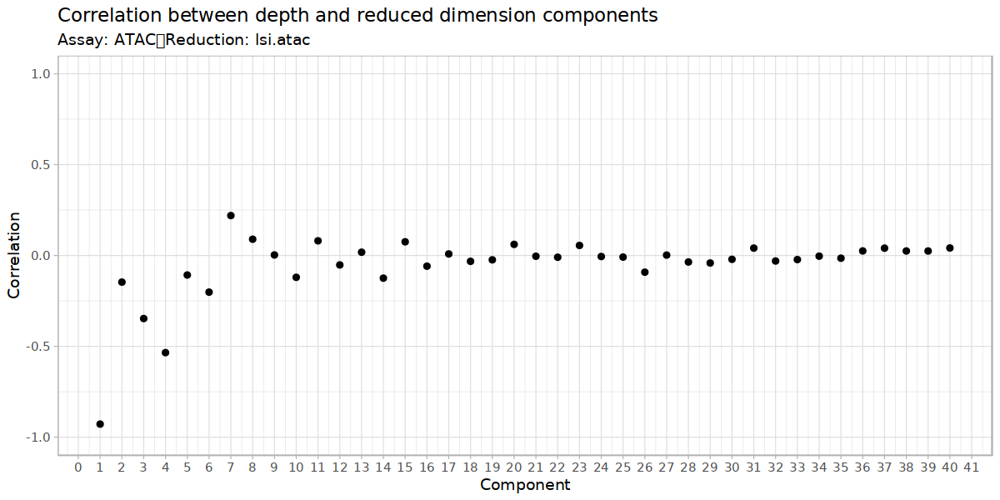

In [46]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

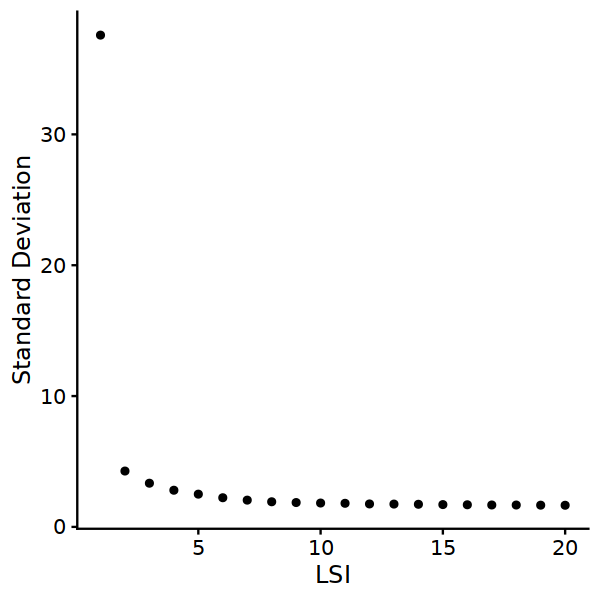

In [47]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [48]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [49]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

19:50:52 UMAP embedding parameters a = 0.115 b = 1.929

19:50:53 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

19:50:55 Initializing from normalized Laplacian + noise (using irlba)

19:50:56 Commencing optimization for 200 epochs, with 365622 positive edges

19:51:14 Optimization finished



In [50]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 12239
Number of edges: 397460

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9774
Number of communities: 10
Elapsed time: 1 seconds


1 singletons identified. 9 final clusters.



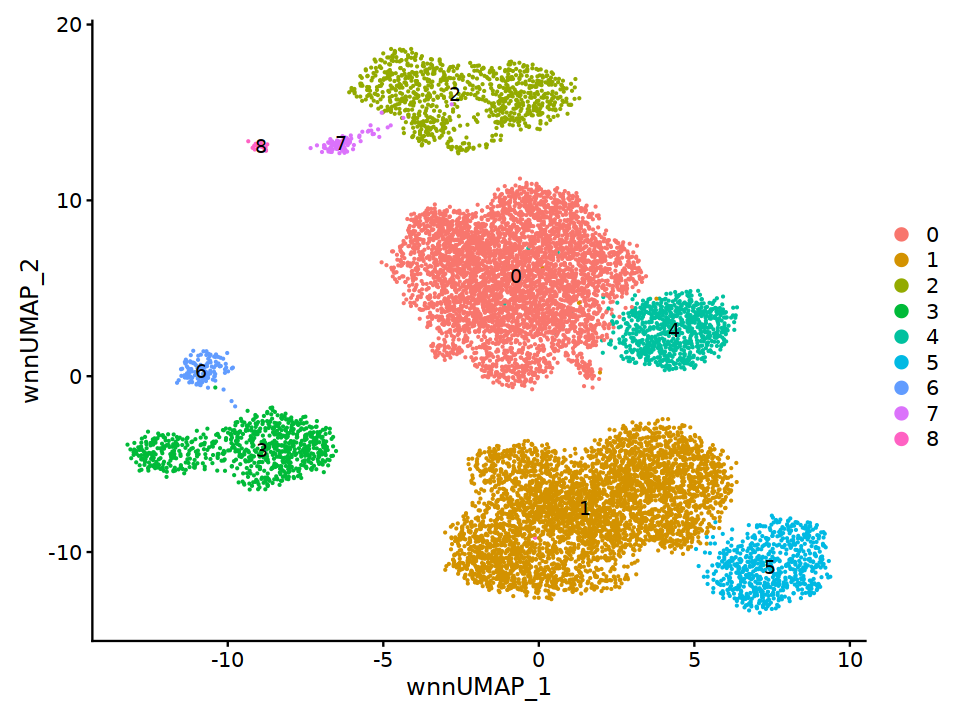

In [51]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [52]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8



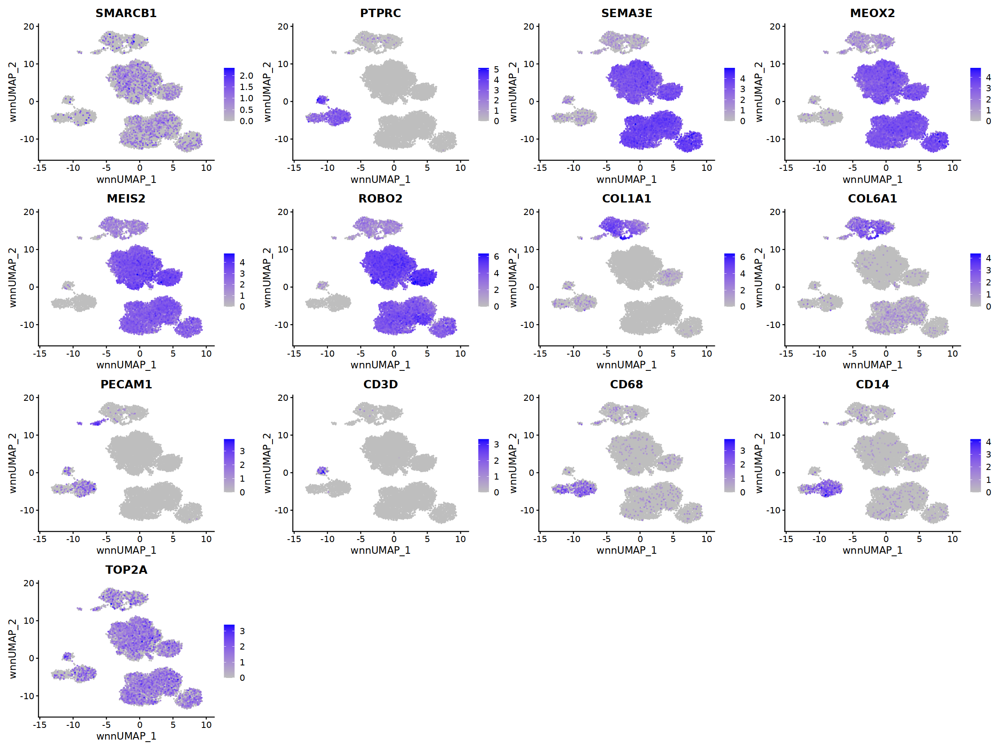

In [53]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC","SEMA3E","MEOX2", "MEIS2","ROBO2",
                              "COL1A1","COL6A1",
                              "PECAM1","CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),order=T)

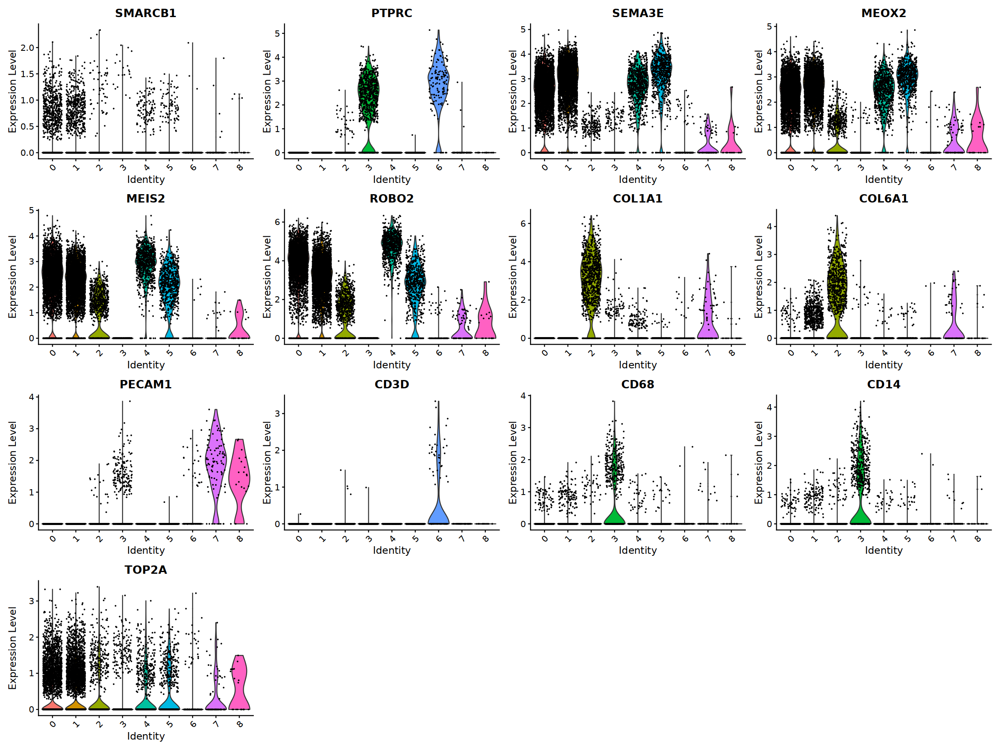

In [54]:
VlnPlot(seurat_obj, feature=vars2plot)

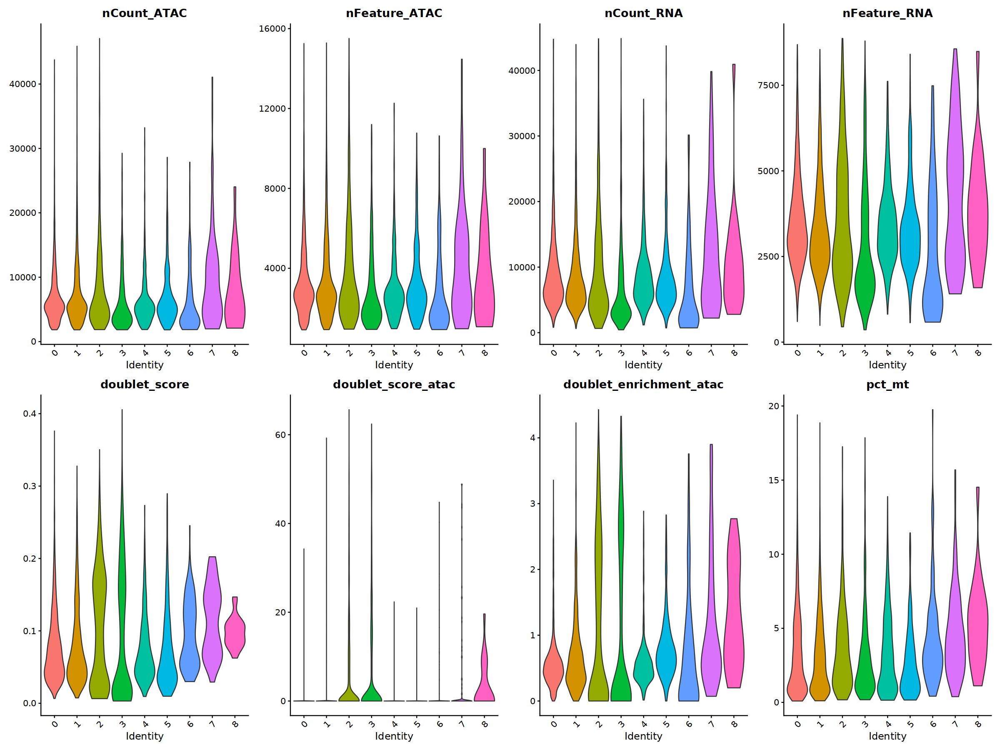

In [55]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

In [56]:
rna.markers %>% 
  dplyr::filter(cluster == "8") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CCL211,0.000000e+00,5.549066,0.952,0.004,0.000000e+00,8,CCL21
PDE7B3,1.870650e-130,4.363787,0.857,0.025,5.929211e-126,8,PDE7B
LDB23,1.383096e-81,4.154240,0.857,0.040,4.383860e-77,8,LDB2
AL357507.11,4.959998e-275,4.050739,0.619,0.005,1.572121e-270,8,AL357507.1
FBXL72,7.792147e-64,4.014665,0.905,0.060,2.469799e-59,8,FBXL7
ZNF5212,6.009980e-70,3.945382,0.810,0.043,1.904923e-65,8,ZNF521
RAPGEF51,2.246682e-129,3.874468,0.810,0.022,7.121082e-125,8,RAPGEF5
PROX1,0.000000e+00,3.749305,0.810,0.002,0.000000e+00,8,PROX1
MMRN1,0.000000e+00,3.674961,0.857,0.001,0.000000e+00,8,MMRN1


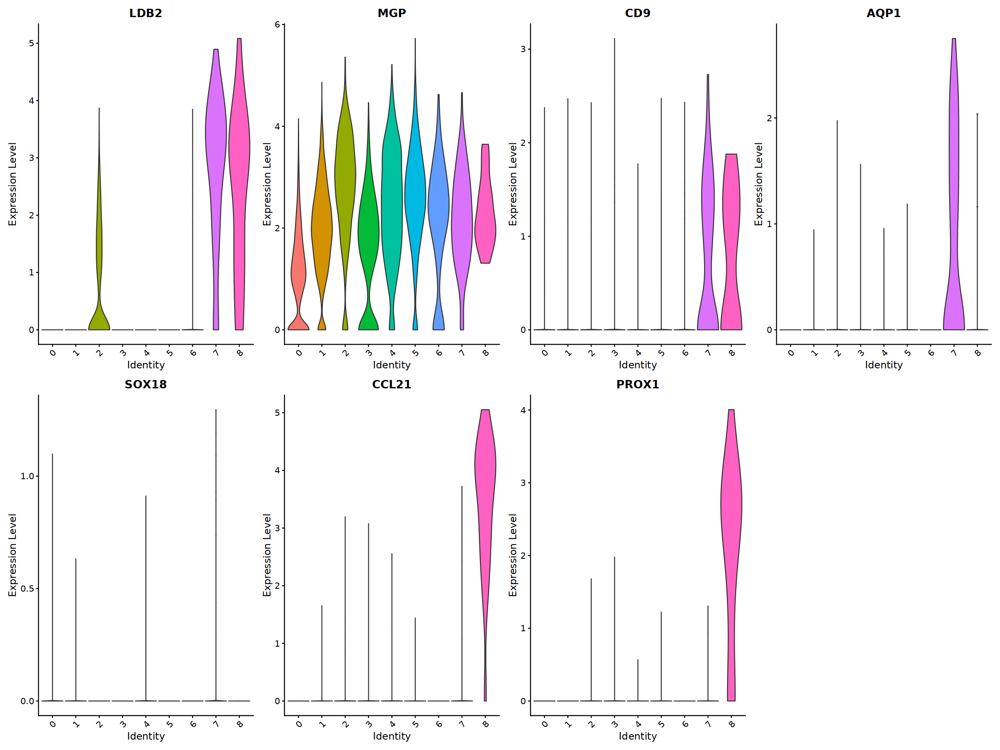

In [57]:
VlnPlot(seurat_obj, feature=c("LDB2", "MGP", "CD9", "AQP1", "SOX18", "CCL21", "PROX1"), ncol = 4, pt.size = 0)

### Rename

In [58]:
rename_clusters <- c("0"="Tumor MECOM", 
                     "1"="Tumor PIK3C2G",
                     "2"="Fibroblast", 
                     "3"="Monocytes-Macrophages",
                     "4"="Tumor PCDH9",
                     "5"="Tumor PDE1A",
                     "6"="T-cells",
                     "7"="Podocytes-Endothelial cells",
                     "8"="Lymphatic Endothelial cells")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [59]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep]

In [60]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [61]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [62]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [63]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune

Calculating cluster Other stromal



In [64]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

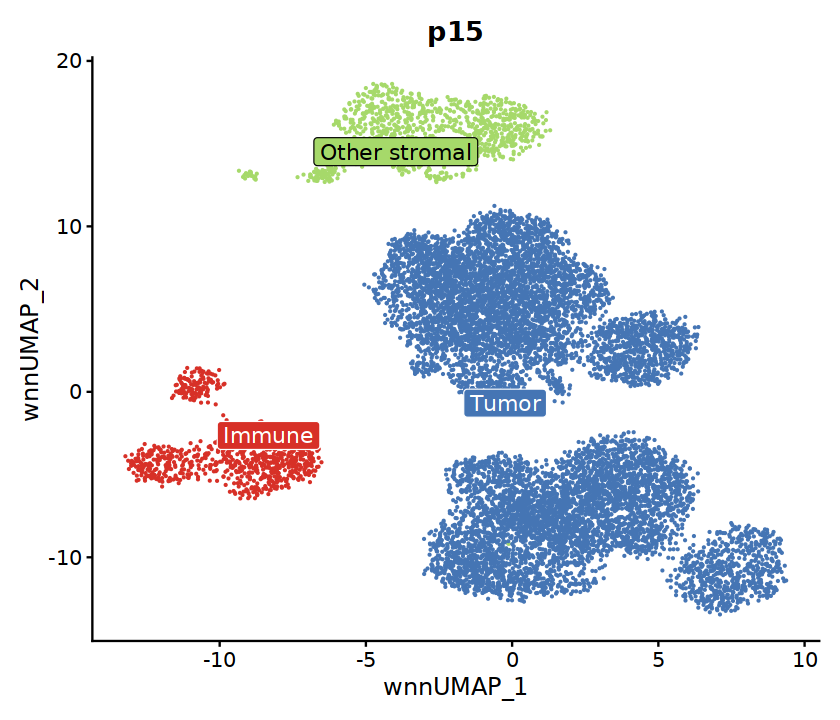

In [65]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [66]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [67]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [68]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

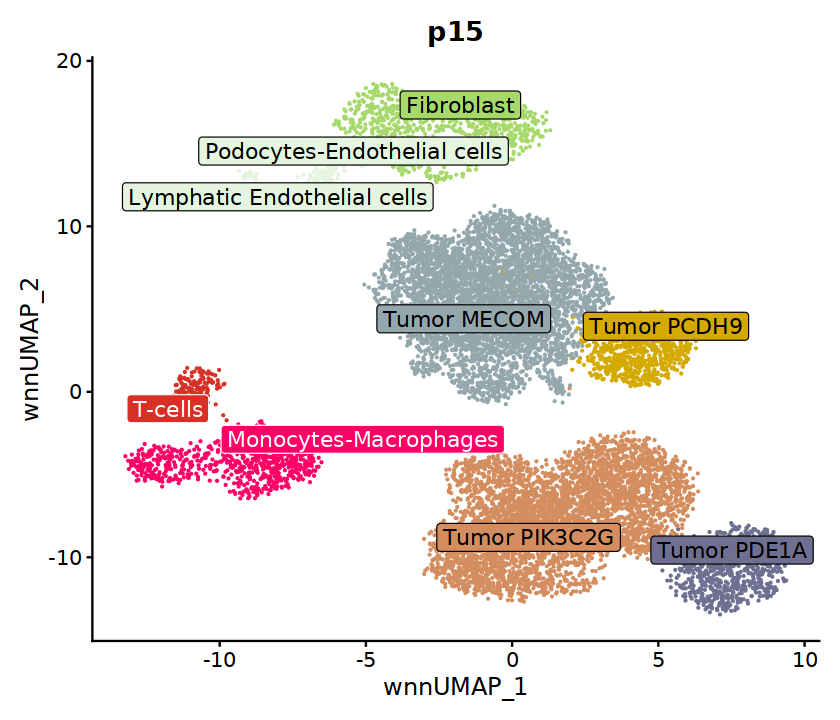

In [69]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [70]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

In [71]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

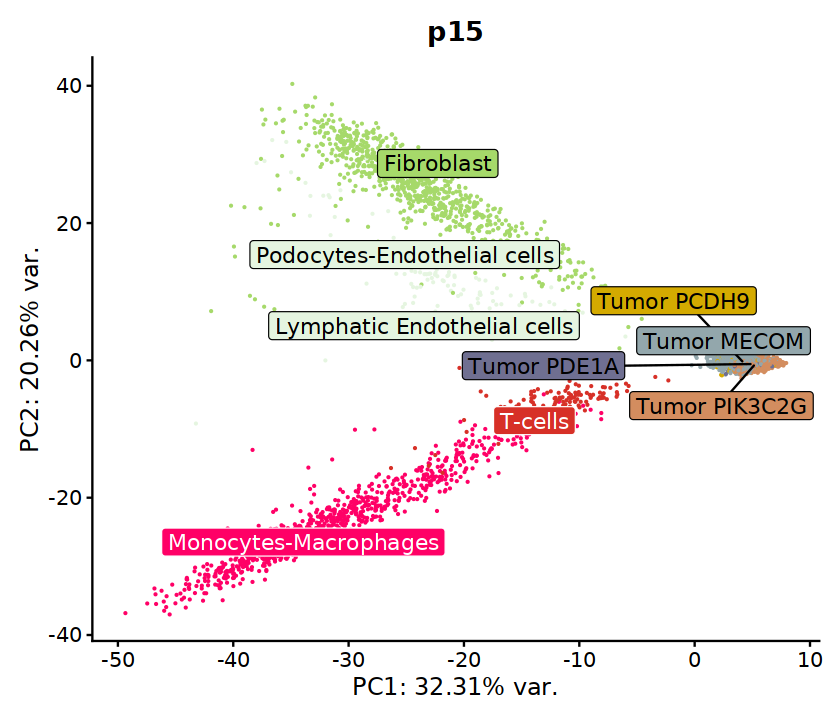

In [72]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

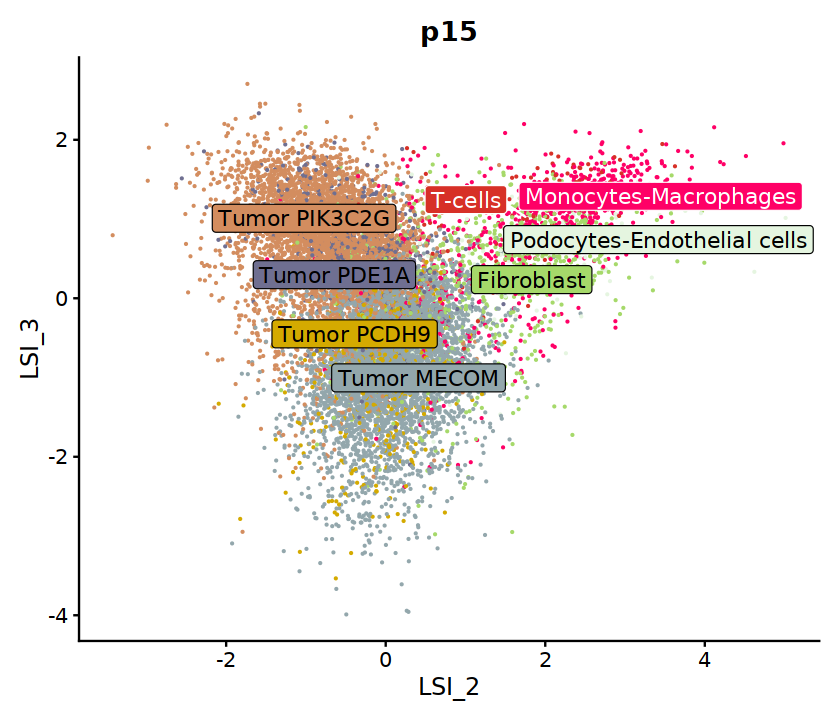

In [73]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

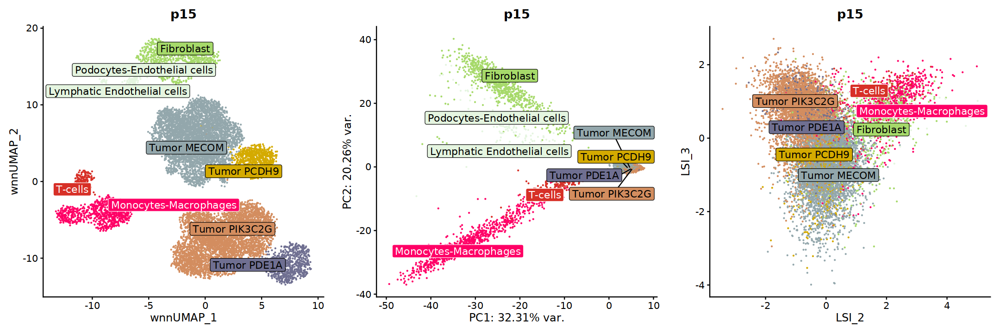

In [74]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [75]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [76]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("MEOX2", "MEIS2", "BMP5"), markers) ## common markers to all clusters

In [77]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

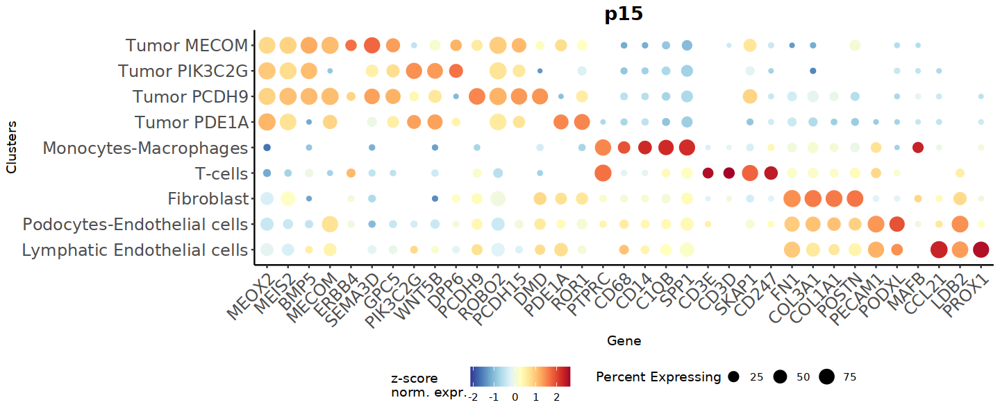

In [78]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, unique(markers), TRUE,patient)
dp1

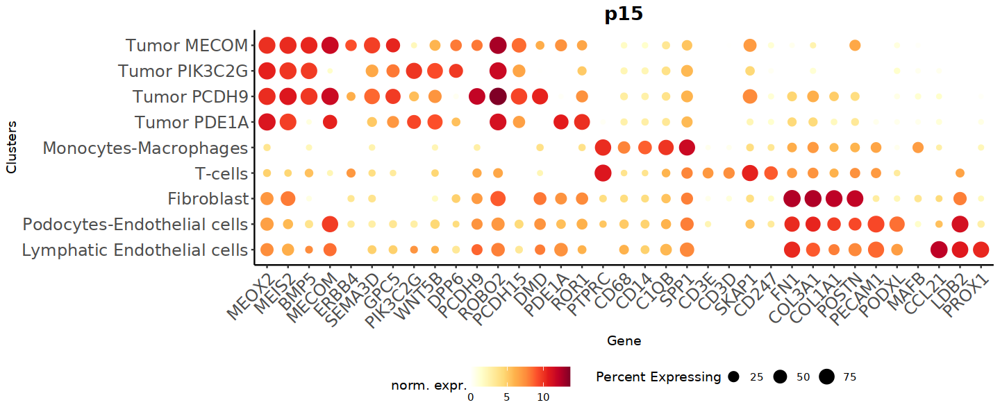

In [79]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, unique(markers), FALSE,patient)
dp2

In [80]:
ggsave(plot = dp1, width = 12, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save 

In [81]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [82]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [ ]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [ ]:
sessionInfo()